# Deepfake Video — Deep Learning trên `dfdc_train_part_15`

Train CNN (transfer learning) **trực tiếp trên video** của `dfdc_train_part_15`:

1. Tìm part 15 + `metadata.json` → nhãn REAL / FAKE
2. Chia train / val / test **theo video gốc** (`original`) — video gốc và mọi bản Fake của nó luôn cùng một tập (chống rò rỉ dữ liệu)
3. Mỗi video: lấy `N_FRAMES` khung hình rải đều → detect + cắt mặt → cache ra đĩa (chỉ làm 1 lần)
4. Fine-tune CNN (EfficientNet-B0 / ResNet) ở mức khung hình: lấy mẫu cân bằng Real/Fake, augmentation trên GPU, AMP
5. Chọn epoch tốt nhất bằng **tập val**; **tập test chỉ đánh giá 1 lần**, ở mức video (trung bình xác suất các khung)
6. Demo trên video + lưu model

> **Quy trình tiết kiệm GPU (2 lần chạy):**
> 1. **Lần 1 — tắt GPU (None/CPU):** notebook chỉ cắt mặt 2000 video và lưu cache `frames_*.npy/.csv` vào `/kaggle/working/dl_cache`. Bấm *Save Version → Save & Run All*.
> 2. **Lần 2 — bật GPU T4:** Add Input → *Notebook Output Files* → chọn notebook ở lần 1. Notebook tự tìm cache, chỉ train trên GPU, tự dừng + lưu model sau `TIME_LIMIT_H` giờ, và tự train tiếp nếu có `dl_video_last.pt`.
> Nếu bật GPU mà không có cache, notebook vẫn tự cắt mặt trong phiên GPU (tốn quota hơn).
>
> **Trước khi chạy:** Add Input dataset chứa `dfdc_train_part_15` (`data-raw`) → Settings → Accelerator → **GPU T4**.
> Không có GPU → notebook chỉ chạy bước cắt mặt rồi dừng (không train).
> Nhãn: `1 = Real`, `0 = Fake` (giống notebook ML).

## 0. Cấu hình

In [1]:
import os, glob, json, time, math, random, copy, hashlib, shutil, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from joblib import Parallel, delayed

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss, confusion_matrix,
                             classification_report, roc_curve)

warnings.filterwarnings("ignore")
%matplotlib inline

T_START = time.time()              # mốc bắt đầu phiên chạy (dùng cho giới hạn thời gian)

# ===================== CẤU HÌNH (chỉnh tại đây) =====================
PART = 15                      # dfdc_train_part_XX
ARCH = "efficientnet_b0"       # "efficientnet_b0" | "resnet18" | "resnet50"
SEED = 42
TEST_SIZE, VAL_SIZE = 0.15, 0.15   # tỉ lệ theo VIDEO GỐC
LR, PATIENCE = 3e-4, 3             # PATIENCE: dừng sớm nếu val không cải thiện sau N epoch
FORCE_REEXTRACT = False            # True = cắt mặt lại từ đầu, bỏ qua cache
TIME_LIMIT_H = 9.0                 # tự dừng train + lưu model khi phiên chạy được ngần này giờ (Kaggle cắt ở 12h)
EXTRACT_LIMIT_H = 3.0              # giới hạn giờ cho bước cắt mặt (quá giờ -> dùng phần đã cắt)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IS_GPU = DEVICE.type == "cuda"
IMG, N_FRAMES, MAX_VIDEOS = 224, 16, 2000   # MAX_VIDEOS=None: dùng HẾT video của part
BATCH, EPOCHS = 64, 8
EXTRACT_ONLY = not IS_GPU          # không có GPU -> chỉ cắt mặt + lưu cache, không train
RUN_TRAIN = IS_GPU
if EXTRACT_ONLY:
    print("[CPU] Chế độ chỉ cắt mặt: chạy xong sẽ lưu cache vào output để lần sau bật GPU train (đỡ tốn quota GPU).")

N_PROC = max(1, os.cpu_count() or 1)
N_WORKERS = min(4, N_PROC)
INPUT_ROOT = "/kaggle/input"
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("work")
if EXTRACT_ONLY:
    CACHE = os.path.join(WORK, "dl_cache")                       # nằm trong output -> dùng làm Input cho lần chạy GPU
else:
    CACHE = "/kaggle/temp/dl_cache" if os.path.isdir("/kaggle/temp") else os.path.join(WORK, "dl_cache")   # không nằm trong output
OUT = os.path.join(WORK, "outputs_dl")
os.makedirs(CACHE, exist_ok=True); os.makedirs(OUT, exist_ok=True)


def find_in_input(*names):
    """Tìm thư mục trong /kaggle/input chứa đủ các file `names` (bỏ qua thư mục ảnh Dataset và thư mục video)."""
    for r, d, f in os.walk(INPUT_ROOT):
        d[:] = [x for x in d if x != "Dataset" and "dfdc_train_part" not in x]
        if all(n in f for n in names):
            return r
    return None



random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Thiết bị:", DEVICE, "-", torch.cuda.get_device_name(0) if IS_GPU else "CPU")
print("ARCH=%s | IMG=%d | N_FRAMES=%d | BATCH=%d | EPOCHS=%d | MAX_VIDEOS=%s | TIME_LIMIT_H=%.1f" % (ARCH, IMG, N_FRAMES, BATCH, EPOCHS, MAX_VIDEOS, TIME_LIMIT_H))

Thiết bị: cuda - Tesla T4
ARCH=efficientnet_b0 | IMG=224 | N_FRAMES=16 | BATCH=64 | EPOCHS=8 | MAX_VIDEOS=2000 | TIME_LIMIT_H=9.0


## 1. Nạp dữ liệu video `dfdc_train_part_15` + nhãn

In [2]:
VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv", ".webm")


def find_part_dir(part, base=INPUT_ROOT, max_depth=7):
    """Thư mục tên chứa 'part_15' và có file video bên trong (không phân biệt hoa thường)."""
    keys = ("part_%02d" % part, "part_%d" % part)
    for r, d, f in os.walk(base):
        d[:] = [x for x in d if x != "Dataset"]          # bỏ qua bộ ảnh Train/Test/Validation cho nhanh
        if r[len(base):].count("/") >= max_depth:
            d[:] = []
            continue
        if any(k in os.path.basename(r).lower() for k in keys) and any(x.lower().endswith(VIDEO_EXTS) for x in f):
            return r
    return None


PART_DIR = find_part_dir(PART)
if PART_DIR is None:
    raise FileNotFoundError("Không thấy thư mục dfdc_train_part_%02d có video trong %s. Hãy Add Input dataset data-raw." % (PART, INPUT_ROOT))

meta_path = None
for d_ in (PART_DIR, os.path.dirname(PART_DIR), os.path.dirname(os.path.dirname(PART_DIR))):
    if os.path.exists(os.path.join(d_, "metadata.json")):
        meta_path = os.path.join(d_, "metadata.json")
        break
if meta_path is None:
    raise FileNotFoundError("Không thấy metadata.json (nhãn REAL/FAKE) cạnh %s" % PART_DIR)
print("Video   :", PART_DIR)
print("Metadata:", meta_path)

with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)
present = set(os.listdir(PART_DIR))

rows = []
for name, m in meta.items():
    if name not in present:
        continue
    is_real = str(m.get("label", "")).upper() == "REAL"
    group = name if is_real else (m.get("original") or name)      # video gốc là nhóm: gốc + các bản Fake cùng 1 nhóm
    rows.append({"file": name, "path": os.path.join(PART_DIR, name), "label": int(is_real), "group": group})
vid_df = pd.DataFrame(rows).sort_values("file").reset_index(drop=True)
if vid_df.empty:
    raise RuntimeError("metadata.json không khớp với file video nào trong %s" % PART_DIR)


def cap_by_group(df, max_videos, seed=SEED):
    """Giới hạn số video nhưng giữ nguyên cả nhóm (gốc + bản Fake của nó)."""
    if not max_videos or len(df) <= max_videos:
        return df
    sizes = df.groupby("group").size().to_dict()
    keys = sorted(sizes)
    random.Random(seed).shuffle(keys)
    keep, n = [], 0
    for g in keys:
        if n + sizes[g] <= max_videos:
            keep.append(g); n += sizes[g]
    return df[df["group"].isin(keep)].reset_index(drop=True)


vid_df = cap_by_group(vid_df, MAX_VIDEOS)
print("Số video dùng: %d (Real=%d, Fake=%d) | %d nhóm video gốc" % (
    len(vid_df), (vid_df.label == 1).sum(), (vid_df.label == 0).sum(), vid_df["group"].nunique()))

Video   : /kaggle/input/datasets/trnganv/data-raw/data/dfdc_train_part_15
Metadata: /kaggle/input/datasets/trnganv/data-raw/data/dfdc_train_part_15/metadata.json
Số video dùng: 2000 (Real=360, Fake=1640) | 360 nhóm video gốc


## 2. Chia train / val / test theo video gốc

In [3]:
def split_by_group(df, test_size=TEST_SIZE, val_size=VAL_SIZE, seed=SEED):
    out = df.copy()
    out["split"] = "train"
    col = out.columns.get_loc("split")
    trv, te = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed).split(df, df["label"], groups=df["group"]))
    out.iloc[te, col] = "test"
    rest = df.iloc[trv]
    _, va = next(GroupShuffleSplit(n_splits=1, test_size=val_size / (1 - test_size), random_state=seed).split(rest, rest["label"], groups=rest["group"]))
    out.iloc[trv[va], col] = "val"
    return out


vid_df = split_by_group(vid_df)
vid_all = vid_df.copy()          # danh sách đầy đủ (trước khi loại video không thấy mặt ở Bước 3)
g = {s: set(vid_df.loc[vid_df.split == s, "group"]) for s in ("train", "val", "test")}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"]), "Rò rỉ nhóm giữa các tập!"
tab = pd.crosstab(vid_df["split"], vid_df["label"].map({1: "Real", 0: "Fake"})).reindex(["train", "val", "test"])
print(tab)
assert (tab.values > 0).all(), "Có tập thiếu 1 lớp — đổi SEED hoặc tăng MAX_VIDEOS."

label  Fake  Real
split            
train  1106   252
val     261    54
test    273    54


## 3. Trích khung hình + cắt mặt (đa tiến trình, cache ra đĩa)

Mỗi video → tối đa `N_FRAMES` khung rải đều → detect mặt lớn nhất (Haar, chạy trên ảnh thu nhỏ) → cắt kèm margin → resize `IMG×IMG`.
Khung không thấy mặt bị bỏ; video không có khung nào có mặt bị loại khỏi dataset.

In [4]:
CASCADE_XML = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"


def read_frames(path, n):
    """Lấy tối đa n khung rải đều. Đọc tuần tự bằng grab() — nhanh hơn seek với video H.264."""
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    if total <= 0:
        cap.release()
        return [], [], fps
    ids = np.unique(np.linspace(0, total - 1, n).astype(int))
    want, last = set(ids.tolist()), int(ids[-1])
    frames, fids = [], []
    for i in range(last + 1):
        if not cap.grab():
            break
        if i in want:
            ok, fr = cap.retrieve()
            if ok:
                frames.append(fr); fids.append(i)
    cap.release()
    return frames, fids, fps


def crop_face(bgr, det, img=IMG, margin=0.3, max_side=480):
    """Mặt lớn nhất (detect trên ảnh thu nhỏ, cắt ở độ phân giải gốc) -> RGB (img,img,3) uint8. Không thấy mặt -> None."""
    h, w = bgr.shape[:2]
    s = min(1.0, max_side / float(max(h, w)))
    small = cv2.resize(bgr, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA) if s < 1.0 else bgr
    faces = det.detectMultiScale(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), scaleFactor=1.1, minNeighbors=5, minSize=(24, 24))
    if len(faces) == 0:
        return None
    x, y, fw, fh = [int(round(v / s)) for v in max(faces, key=lambda f: f[2] * f[3])]
    mx, my = int(fw * margin), int(fh * margin)
    x0, y0, x1, y1 = max(0, x - mx), max(0, y - my), min(w, x + fw + mx), min(h, y + fh + my)
    face = bgr[y0:y1, x0:x1]
    if face.size == 0:
        return None
    return cv2.cvtColor(cv2.resize(face, (img, img), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)


def extract_faces(path, n, img):
    """Chạy ở tiến trình con: video -> ((k,img,img,3) uint8 RGB, id khung hình). Lỗi / không có mặt -> None."""
    try:
        cv2.setNumThreads(1)
        det = cv2.CascadeClassifier(CASCADE_XML)
        frames, fids, _ = read_frames(path, n)
        crops, keep = [], []
        for fr, fid in zip(frames, fids):
            c = crop_face(fr, det, img)
            if c is not None:
                crops.append(c); keep.append(fid)
        return (np.stack(crops), np.array(keep)) if crops else None
    except Exception:
        return None

[WARN] Không thấy cache khung mặt -> đang cắt mặt ngay trong phiên GPU (tốn quota GPU). Lần sau hãy chạy bước này bằng CPU rồi Add Input output của nó.


Đọc video + cắt mặt:   0%|          | 0/2000 [00:00<?, ?it/s]

[OK] 26844 khung mặt từ 1926 video | bỏ 74 video (không đọc được / không thấy mặt)
Mất 49.3 phút
label   Fake  Real    All
split                    
train  14808  3228  18036
val     3700   738   4438
test    3674   696   4370
All    22182  4662  26844


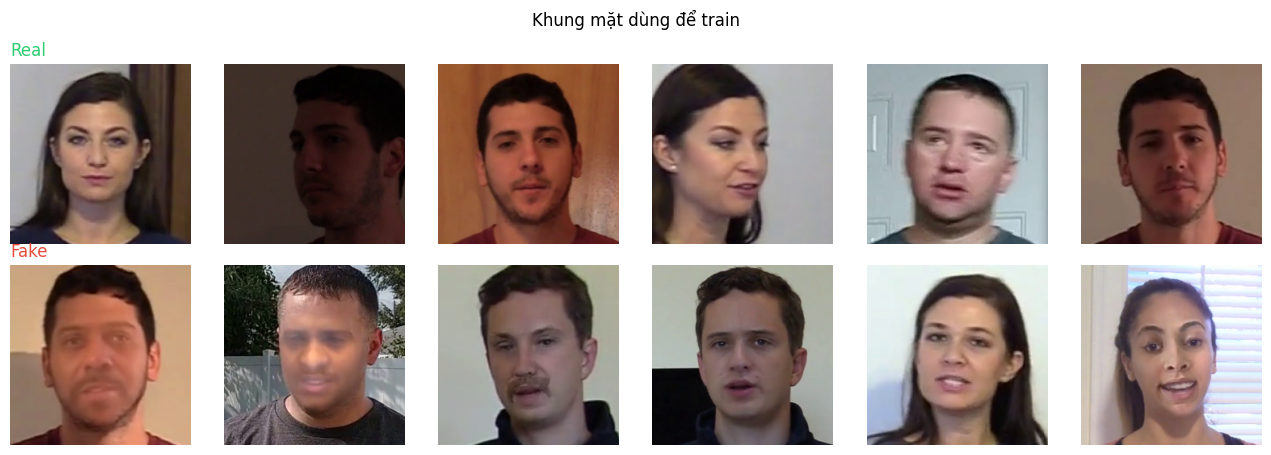

In [5]:
tag = hashlib.md5(",".join(sorted(vid_all["file"])).encode()).hexdigest()[:8]
FNAME = "frames_%s_%d_%d.npy" % (tag, IMG, N_FRAMES)
FRAMES_NPY = os.path.join(CACHE, FNAME)
INDEX_CSV = FRAMES_NPY.replace(".npy", ".csv")


def have_cache():
    return os.path.exists(FRAMES_NPY) and os.path.exists(INDEX_CSV)


def build_faces_cache(df):
    arr = np.lib.format.open_memmap(FRAMES_NPY, mode="w+", dtype=np.uint8, shape=(len(df) * N_FRAMES, IMG, IMG, 3))
    try:
        par = Parallel(n_jobs=N_PROC, return_as="generator")
    except TypeError:                                   # joblib cũ: trả về list
        par = Parallel(n_jobs=N_PROC)
    gen = par(delayed(extract_faces)(p, N_FRAMES, IMG) for p in df["path"])

    recs, n, failed, t0, stopped = [], 0, [], time.time(), False
    for (_, r), res in zip(df.iterrows(), tqdm(gen, total=len(df), desc="Đọc video + cắt mặt")):
        if (time.time() - t0) / 3600 > EXTRACT_LIMIT_H:
            print("[STOP] Quá %.1f giờ cắt mặt -> dùng phần đã cắt (%d video). Tăng EXTRACT_LIMIT_H nếu muốn cắt tiếp." % (EXTRACT_LIMIT_H, len(recs)))
            stopped = True
            break
        if res is None:
            failed.append(r["file"])
            continue
        crops, fids = res
        k = len(crops)
        arr[n:n + k] = crops
        recs.append(pd.DataFrame({"row": np.arange(n, n + k), "file": r["file"], "label": r["label"], "group": r["group"], "fid": fids}))
        n += k
    if stopped:
        try:
            gen.close()
        except Exception:
            pass
    arr.flush(); del arr
    if not recs:
        raise RuntimeError("Không cắt được khung mặt nào (video không đọc được / không thấy mặt).")
    idx = pd.concat(recs, ignore_index=True)
    idx.to_csv(INDEX_CSV, index=False)
    print("[OK] %d khung mặt từ %d video | bỏ %d video (không đọc được / không thấy mặt)" % (len(idx), len(recs), len(failed)))
    return idx


# Chưa có cache ở CACHE -> tìm cache của lần chạy trước trong Input (Add Input -> Notebook Output Files)
if not have_cache() and not FORCE_REEXTRACT:
    src_dir = find_in_input(FNAME, FNAME.replace(".npy", ".csv"))
    if src_dir:
        src_npy = os.path.join(src_dir, FNAME)
        src_csv = src_npy.replace(".npy", ".csv")
        free = shutil.disk_usage(CACHE).free
        if EXTRACT_ONLY or free < os.path.getsize(src_npy) * 1.1:
            FRAMES_NPY, INDEX_CSV = src_npy, src_csv                    # đọc thẳng từ Input
            print("[CACHE] Dùng cache có sẵn trong Input:", FRAMES_NPY)
        else:
            t_cp = time.time()
            shutil.copy(src_csv, INDEX_CSV); shutil.copy(src_npy, FRAMES_NPY)   # copy ra đĩa cục bộ cho đọc ngẫu nhiên nhanh
            print("[CACHE] Đã copy cache từ Input (%.0fs): %s" % (time.time() - t_cp, FRAMES_NPY))

if have_cache() and not FORCE_REEXTRACT:
    print("[CACHE] Dùng lại", FRAMES_NPY)
    frames_df = pd.read_csv(INDEX_CSV)
else:
    if IS_GPU:
        print("[WARN] Không thấy cache khung mặt -> đang cắt mặt ngay trong phiên GPU (tốn quota GPU). "
              "Lần sau hãy chạy bước này bằng CPU rồi Add Input output của nó.")
    t0 = time.time()
    frames_df = build_faces_cache(vid_all)
    print("Mất %.1f phút" % ((time.time() - t0) / 60))

vid_df = vid_all[vid_all["file"].isin(set(frames_df["file"]))].reset_index(drop=True)
frames_df = frames_df.merge(vid_df[["file", "split"]], on="file", how="left")

print(pd.crosstab(frames_df["split"], frames_df["label"].map({1: "Real", 0: "Fake"}), margins=True).reindex(["train", "val", "test", "All"]))

# Xem thử khung mặt đã cắt (hàng 1: Real, hàng 2: Fake)
_arr = np.load(FRAMES_NPY, mmap_mode="r")
fig, axs = plt.subplots(2, 6, figsize=(13, 4.6))
for r_, lbl in enumerate((1, 0)):
    sub = frames_df[(frames_df["split"] == "train") & (frames_df["label"] == lbl)]
    pick = sub.sample(min(6, len(sub)), random_state=0)["row"].values
    for c_ in range(6):
        axs[r_, c_].axis("off")
        if c_ < len(pick):
            axs[r_, c_].imshow(_arr[pick[c_]])
    axs[r_, 0].set_title("Real" if lbl == 1 else "Fake", loc="left", color="#2ecc71" if lbl == 1 else "#e74c3c")
plt.suptitle("Khung mặt dùng để train"); plt.tight_layout(); plt.show()
del _arr

if EXTRACT_ONLY:
    print("\n[XONG BƯỚC CẮT MẶT - chế độ CPU] Cache: %s (%.2f GB)" % (FRAMES_NPY, os.path.getsize(FRAMES_NPY) / 1e9))
    print("Tiếp theo: Save Version -> Save & Run All. Xong, mở notebook mới/bản này, bật GPU T4, Add Input -> Notebook Output Files -> chọn notebook này, rồi chạy lại.")

## 4. Dataset, augmentation trên GPU, model, hàm đánh giá

- Augmentation (lật ngang, zoom/dịch nhẹ, đổi sáng/tương phản) chạy **trên GPU** nên không nghẽn CPU.
- Mức khung hình → mức video: **trung bình P(Real)** của các khung.
- Ngoài accuracy/F1 còn có **balanced accuracy, AUC, log-loss** vì part 15 lệch lớp (Fake nhiều hơn Real).

In [6]:
if RUN_TRAIN:
    MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
    STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    AMP = IS_GPU


    def autocast():
        return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP)


    class FrameDS(Dataset):
        """Đọc khung mặt (uint8, HWC) từ file npy bằng memmap — mỗi worker tự mở file. Nhãn: 1 = Real, 0 = Fake."""
        def __init__(self, npy_path, rows, labels):
            self.npy_path = npy_path
            self.rows = np.asarray(rows)
            self.labels = np.asarray(labels, dtype=np.int64)
            self.arr = None

        def __len__(self):
            return len(self.rows)

        def __getitem__(self, i):
            if self.arr is None:
                self.arr = np.load(self.npy_path, mmap_mode="r")
            return torch.from_numpy(np.ascontiguousarray(self.arr[self.rows[i]])), int(self.labels[i])


    def to_input(xb, train):
        """uint8 (B,H,W,3) -> tensor chuẩn hoá trên GPU; train=True thì augment từng mẫu."""
        x = xb.to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float().div_(255.0)
        if train:
            B = x.size(0)
            s = torch.empty(B, device=DEVICE).uniform_(0.85, 1.0)                       # zoom
            flip = (torch.rand(B, device=DEVICE) < 0.5).float() * 2 - 1                 # lật ngang
            theta = torch.zeros(B, 2, 3, device=DEVICE)
            theta[:, 0, 0] = s * flip
            theta[:, 1, 1] = s
            theta[:, 0, 2] = torch.empty(B, device=DEVICE).uniform_(-0.08, 0.08)        # dịch
            theta[:, 1, 2] = torch.empty(B, device=DEVICE).uniform_(-0.08, 0.08)
            grid = F.affine_grid(theta, list(x.shape), align_corners=False)
            x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
            c = torch.empty(B, 1, 1, 1, device=DEVICE).uniform_(0.8, 1.2)               # tương phản
            b = torch.empty(B, 1, 1, 1, device=DEVICE).uniform_(-0.08, 0.08)            # độ sáng
            x = ((x - 0.5) * c + 0.5 + b).clamp_(0, 1)
        return (x - MEAN) / STD


    ARCHS = {"resnet18": ("resnet18", "ResNet18_Weights"),
             "resnet50": ("resnet50", "ResNet50_Weights"),
             "efficientnet_b0": ("efficientnet_b0", "EfficientNet_B0_Weights")}


    def build_model(arch, pretrained=True):
        fn_name, w_name = ARCHS[arch]
        fn = getattr(tvm, fn_name)
        try:
            m = fn(weights=getattr(tvm, w_name).DEFAULT if pretrained else None)
        except Exception as e:
            print("[WARN] Không tải được trọng số pretrained (%s) -> khởi tạo ngẫu nhiên. "
                  "Bật Internet trong Settings để tải trọng số ImageNet (kết quả tốt hơn nhiều)." % e)
            m = fn(weights=None)
        if arch.startswith("resnet"):
            m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, 2))
        else:
            m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, 2))
        return m


    @torch.no_grad()
    def predict_frames(model, rows, batch=BATCH * 2):
        """P(Real) cho các khung (theo chỉ số hàng trong file npy)."""
        dl = DataLoader(FrameDS(FRAMES_NPY, rows, np.zeros(len(rows), dtype=np.int64)), batch_size=batch,
                        shuffle=False, num_workers=N_WORKERS, pin_memory=IS_GPU)
        model.eval(); out = []
        for xb, _ in dl:
            with autocast():
                logits = model(to_input(xb, False))
            out.append(F.softmax(logits.float(), 1)[:, 1].cpu().numpy())
        return np.concatenate(out)


    @torch.no_grad()
    def predict_array(model, arr, batch=64):
        """P(Real) cho mảng khung mặt RGB uint8 (N,H,W,3)."""
        model.eval(); out = []
        for i in range(0, len(arr), batch):
            xb = torch.from_numpy(np.ascontiguousarray(arr[i:i + batch]))
            with autocast():
                logits = model(to_input(xb, False))
            out.append(F.softmax(logits.float(), 1)[:, 1].cpu().numpy())
        return np.concatenate(out)


    def video_scores(sub, p):
        """Gộp P(Real) từng khung -> mỗi video 1 điểm (trung bình). `sub` phải cùng thứ tự với `p`."""
        d = sub[["file", "label"]].copy()
        d["p"] = np.asarray(p)
        return d.groupby("file", sort=False).agg(label=("label", "first"), p_real=("p", "mean"), n_frames=("p", "size")).reset_index()


    def calc_metrics(y, p, thr=0.5):
        y = np.asarray(y); p = np.asarray(p, dtype=float); pred = (p >= thr).astype(int)
        try:
            auc = float(roc_auc_score(y, p))
        except ValueError:
            auc = float("nan")
        return {"accuracy": float(accuracy_score(y, pred)), "balanced_acc": float(balanced_accuracy_score(y, pred)),
                "precision": float(precision_score(y, pred, zero_division=0)), "recall": float(recall_score(y, pred, zero_division=0)),
                "f1": float(f1_score(y, pred, zero_division=0)), "f1_macro": float(f1_score(y, pred, average="macro", zero_division=0)),
                "auc": auc, "logloss": float(log_loss(y, np.clip(p, 1e-3, 1 - 1e-3), labels=[0, 1]))}


    def evaluate(model, sub):
        """Trả về (p_khung, bảng_video, metric_khung, metric_video) cho 1 tập khung hình."""
        p = predict_frames(model, sub["row"].values)
        vs = video_scores(sub, p)
        return p, vs, calc_metrics(sub["label"].values, p), calc_metrics(vs["label"].values, vs["p_real"].values)


    def make_scaler(enabled):
        try:
            return torch.amp.GradScaler("cuda", enabled=enabled)
        except (AttributeError, TypeError):
            return torch.cuda.amp.GradScaler(enabled=enabled)


    m_try = build_model(ARCH)
    print("%s: %.2fM tham số" % (ARCH, sum(p.numel() for p in m_try.parameters()) / 1e6))
    del m_try

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 163MB/s]


efficientnet_b0: 4.01M tham số


## 5. Huấn luyện

- Lấy mẫu **cân bằng Real/Fake** ở mức khung hình (`WeightedRandomSampler`), label smoothing 0.05, AdamW + OneCycleLR.
- Mỗi epoch đánh giá trên **val** (khung + video). Checkpoint tốt nhất theo **log-loss video trên val**; dừng sớm nếu không cải thiện.

Train: 18036 khung (Real=3228, Fake=14808) | Val: 4438 | Test: 4370


epoch 1/8:   0%|          | 0/281 [00:00<?, ?it/s]

[epoch 1/8] loss 0.3772 acc 0.8397 | val khung: acc 0.9331 auc 0.9869 | val video: acc 0.9325 bacc 0.9287 auc 0.9915 logloss 0.1659 | 83s  <- tốt nhất


epoch 2/8:   0%|          | 0/281 [00:00<?, ?it/s]

[epoch 2/8] loss 0.1596 acc 0.9805 | val khung: acc 0.9714 auc 0.9970 | val video: acc 0.9775 bacc 0.9711 auc 0.9985 logloss 0.0870 | 55s  <- tốt nhất


...

[epoch 6/8] loss 0.1317 acc 0.9913 | val khung: acc 0.9914 auc 0.9988 | val video: acc 0.9904 bacc 0.9712 auc 0.9996 logloss 0.0519 | 53s


epoch 7/8:   0%|          | 0/281 [00:00<?, ?it/s]

[epoch 7/8] loss 0.1303 acc 0.9920 | val khung: acc 0.9932 auc 0.9992 | val video: acc 0.9904 bacc 0.9788 auc 0.9999 logloss 0.0498 | 54s


epoch 8/8:   0%|          | 0/281 [00:00<?, ?it/s]

[epoch 8/8] loss 0.1297 acc 0.9924 | val khung: acc 0.9935 auc 0.9993 | val video: acc 0.9904 bacc 0.9788 auc 0.9998 logloss 0.0483 | 53s  <- tốt nhất

Epoch tốt nhất: 8 (val video logloss = 0.0483) -> /kaggle/working/outputs_dl/dl_video_best.pt


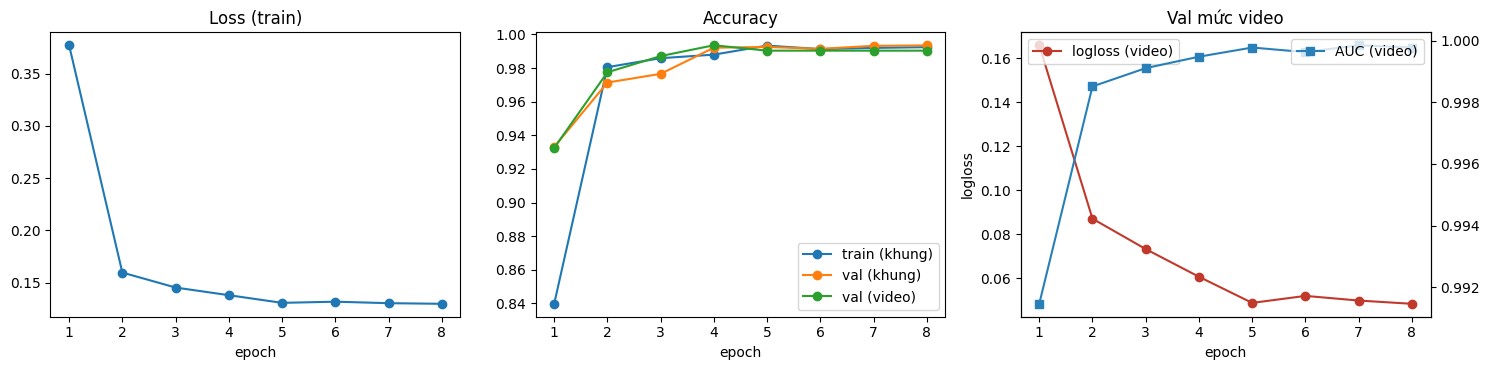

,epoch,train_loss,train_acc,val_frame_acc,val_frame_auc,val_video_acc,val_video_bacc,val_video_auc,val_video_logloss,sec
0,1,0.377180,0.839746,0.933078,0.986866,0.932476,0.928720,0.991461,0.165921,82.799272
1,2,0.159615,0.980538,0.971384,0.997046,0.977492,0.971117,0.998515,0.087039,54.628458
2,3,0.145289,0.985876,0.976566,0.997153,0.987138,0.976908,0.999109,0.073221,53.289862
3,4,0.137966,0.987989,0.992114,0.997688,0.993569,0.988454,0.999480,0.060634,53.243006
4,5,0.130617,0.993383,0.992564,0.999056,0.990354,0.986524,0.999777,0.048743,53.531863
5,6,0.131736,0.991270,0.991438,0.998766,0.990354,0.971154,0.999629,0.051924,53.156502
6,7,0.130310,0.991993,0.993240,0.999212,0.990354,0.978839,0.999851,0.049813,53.724090
7,8,0.129721,0.992438,0.993466,0.999324,0.990354,0.978839,0.999777,0.048334,53.078507


In [7]:
if RUN_TRAIN:
    train_f = frames_df[frames_df["split"] == "train"].reset_index(drop=True)
    val_f = frames_df[frames_df["split"] == "val"].reset_index(drop=True)
    test_f = frames_df[frames_df["split"] == "test"].reset_index(drop=True)

    y_tr = train_f["label"].values
    cnt = np.bincount(y_tr, minlength=2)
    print("Train: %d khung (Real=%d, Fake=%d) | Val: %d | Test: %d" % (len(train_f), cnt[1], cnt[0], len(val_f), len(test_f)))

    sample_w = (1.0 / np.maximum(cnt, 1))[y_tr]
    sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double), num_samples=len(y_tr), replacement=True)
    train_loader = DataLoader(FrameDS(FRAMES_NPY, train_f["row"].values, y_tr), batch_size=BATCH, sampler=sampler,
                              num_workers=N_WORKERS, pin_memory=IS_GPU, drop_last=True, persistent_workers=N_WORKERS > 0,
                              timeout=300 if N_WORKERS > 0 else 0)     # worker kẹt > 5 phút -> báo lỗi thay vì treo vô hạn


    def time_up():
        return (time.time() - T_START) / 3600 >= TIME_LIMIT_H


    BEST_PATH = os.path.join(OUT, "dl_video_best.pt")
    LAST_PATH = os.path.join(OUT, "dl_video_last.pt")
    model = build_model(ARCH).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.15)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = make_scaler(AMP)

    hist, best, bad = [], {"logloss": float("inf"), "epoch": 0}, 0
    start_ep, stopped_by_time = 1, False

    # ---- Train tiếp từ lần trước (dl_video_last.pt trong output hiện tại hoặc trong Input) ----
    if not os.path.exists(LAST_PATH):
        _src = find_in_input("dl_video_last.pt", "dl_video_best.pt")
        if _src:
            shutil.copy(os.path.join(_src, "dl_video_last.pt"), LAST_PATH)
            shutil.copy(os.path.join(_src, "dl_video_best.pt"), BEST_PATH)
    if os.path.exists(LAST_PATH):
        st = torch.load(LAST_PATH, map_location=DEVICE, weights_only=False)
        if st.get("arch") == ARCH and st.get("total_epochs") == EPOCHS and st.get("n_train") == len(train_f):
            model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"])
            scaler.load_state_dict(st["scaler"])
            hist, best, bad = st["hist"], st["best"], st["bad"]
            start_ep = EPOCHS + 1 if st.get("done") else st["epoch"] + 1
            print("[RESUME] Tiếp tục từ epoch %d (tốt nhất: epoch %d)%s" % (start_ep, best["epoch"], " - đã train xong, bỏ qua train" if st.get("done") else ""))
        else:
            print("[RESUME] Bỏ qua checkpoint cũ vì cấu hình (ARCH / EPOCHS / dữ liệu) khác -> train từ đầu.")
        del st

    for ep in range(start_ep, EPOCHS + 1):
        model.train(); t0 = time.time(); tl = tc = n = 0
        for step, (xb, yb) in enumerate(tqdm(train_loader, desc="epoch %d/%d" % (ep, EPOCHS), leave=False)):
            if step % 50 == 0 and time_up():
                stopped_by_time = True
                break
            x, y = to_input(xb, True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast():
                out = model(x)
                loss = crit(out.float(), y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        if stopped_by_time:
            print("[TIME LIMIT] Đã chạy %.1f giờ >= TIME_LIMIT_H=%.1f -> dừng train, dùng checkpoint tốt nhất." % ((time.time() - T_START) / 3600, TIME_LIMIT_H))
            break

        _, _, fm, vm = evaluate(model, val_f)
        row = {"epoch": ep, "train_loss": tl / n, "train_acc": tc / n,
               "val_frame_acc": fm["accuracy"], "val_frame_auc": fm["auc"],
               "val_video_acc": vm["accuracy"], "val_video_bacc": vm["balanced_acc"], "val_video_auc": vm["auc"],
               "val_video_logloss": vm["logloss"], "sec": time.time() - t0}
        hist.append(row)

        star = ""
        if vm["logloss"] < best["logloss"]:
            best, bad, star = {"logloss": vm["logloss"], "epoch": ep}, 0, "  <- tốt nhất"
            torch.save({"state_dict": model.state_dict(), "arch": ARCH, "img": IMG, "n_frames": N_FRAMES, "epoch": ep,
                        "val_video": vm}, BEST_PATH)
        else:
            bad += 1
        done = bad >= PATIENCE or ep == EPOCHS
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                    "hist": hist, "best": best, "bad": bad, "epoch": ep, "arch": ARCH, "total_epochs": EPOCHS,
                    "n_train": len(train_f), "done": done}, LAST_PATH)          # checkpoint mỗi epoch -> mất phiên vẫn train tiếp được
        print("[epoch %d/%d] loss %.4f acc %.4f | val khung: acc %.4f auc %.4f | val video: acc %.4f bacc %.4f auc %.4f logloss %.4f | %.0fs%s" % (
            ep, EPOCHS, row["train_loss"], row["train_acc"], fm["accuracy"], fm["auc"],
            vm["accuracy"], vm["balanced_acc"], vm["auc"], vm["logloss"], row["sec"], star))
        if bad >= PATIENCE:
            print("[EARLY STOP] val không cải thiện sau %d epoch." % PATIENCE)
            break

    if not os.path.exists(BEST_PATH):      # chưa có epoch nào hoàn chỉnh -> lưu model hiện tại để các bước sau vẫn chạy được
        torch.save({"state_dict": model.state_dict(), "arch": ARCH, "img": IMG, "n_frames": N_FRAMES, "epoch": 0, "val_video": {}}, BEST_PATH)
        print("[WARN] Chưa hoàn thành epoch nào -> lưu model hiện tại (chưa được chọn theo val).")
    print("\nEpoch tốt nhất: %d (val video logloss = %.4f) -> %s" % (best["epoch"], best["logloss"], BEST_PATH))
    del train_loader

    h = pd.DataFrame(hist)
    if len(h):
        h.to_csv(os.path.join(OUT, "training_history.csv"), index=False)
        fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
        axs[0].plot(h["epoch"], h["train_loss"], "o-"); axs[0].set_title("Loss (train)")
        axs[1].plot(h["epoch"], h["train_acc"], "o-", label="train (khung)")
        axs[1].plot(h["epoch"], h["val_frame_acc"], "o-", label="val (khung)")
        axs[1].plot(h["epoch"], h["val_video_acc"], "o-", label="val (video)"); axs[1].set_title("Accuracy"); axs[1].legend()
        axs[2].plot(h["epoch"], h["val_video_logloss"], "o-", color="#c0392b", label="logloss (video)")
        axs[2].set_ylabel("logloss"); axs[2].legend(loc="upper left")
        ax2 = axs[2].twinx(); ax2.plot(h["epoch"], h["val_video_auc"], "s-", color="#2980b9", label="AUC (video)"); ax2.legend(loc="upper right")
        axs[2].set_title("Val mức video")
        for a in axs: a.set_xlabel("epoch")
        plt.tight_layout(); plt.savefig(os.path.join(OUT, "training_curve.png"), dpi=150); plt.show()
    display(h)

## 6. Đánh giá trên tập test (video chưa từng thấy)

Nạp checkpoint tốt nhất (chọn bằng val). Ngoài ngưỡng 0.5 còn báo cáo **ngưỡng chọn trên val** (Youden) — hữu ích khi dữ liệu lệch lớp. Test **không** được dùng để chọn epoch hay ngưỡng.

Nạp checkpoint epoch 8 (efficientnet_b0, IMG=224)
Test: 312 video (Real=51, Fake=261)

              precision    recall  f1-score   support

        Fake     0.9849    1.0000    0.9924       261
        Real     1.0000    0.9216    0.9592        51

    accuracy                         0.9872       312
   macro avg     0.9925    0.9608    0.9758       312
weighted avg     0.9874    0.9872    0.9870       312



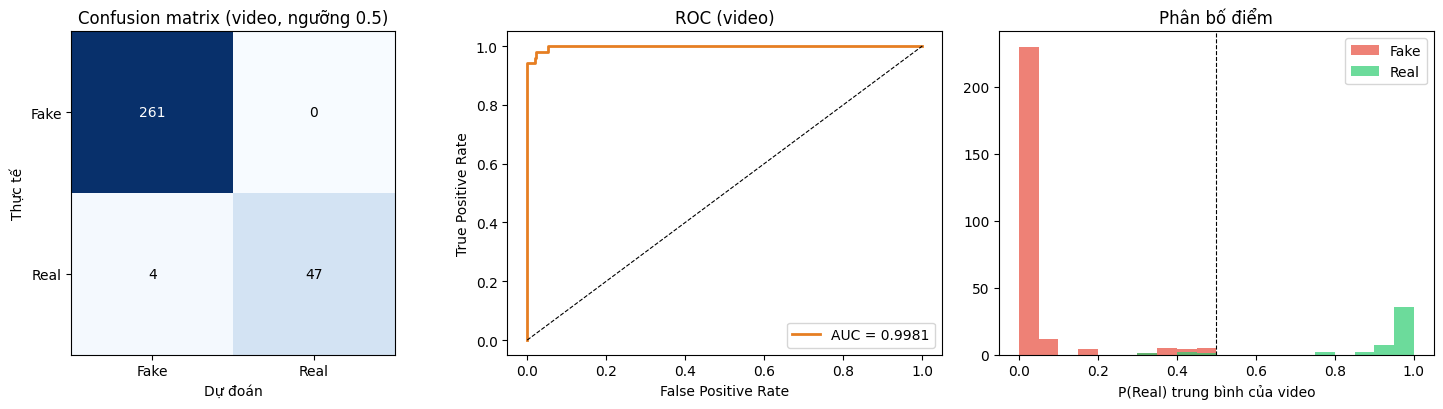

,mức,accuracy,balanced_acc,precision,recall,f1,f1_macro,auc,logloss
0,khung hình (ngưỡng 0.5),0.9879,0.9689,0.9820,0.9411,0.9611,0.9770,0.9973,0.0610
1,VIDEO (ngưỡng 0.5),0.9872,0.9608,1.0000,0.9216,0.9592,0.9758,0.9981,0.0676
2,VIDEO (ngưỡng val = 0.45),0.9776,0.9629,0.9231,0.9412,0.9320,0.9593,0.9981,0.0676


In [8]:
if RUN_TRAIN:
    ck = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)
    best_model = build_model(ck["arch"], pretrained=False).to(DEVICE)
    best_model.load_state_dict(ck["state_dict"]); best_model.eval()
    print("Nạp checkpoint epoch %d (%s, IMG=%d)" % (ck["epoch"], ck["arch"], ck["img"]))

    # Ngưỡng chọn trên VAL (max TPR - FPR)
    _, val_vs, _, _ = evaluate(best_model, val_f)
    fpr_v, tpr_v, thr_v = roc_curve(val_vs["label"], val_vs["p_real"])
    THR_VAL = float(thr_v[np.argmax(tpr_v - fpr_v)])
    if not np.isfinite(THR_VAL):
        THR_VAL = 0.5

    p_te, test_vs, fm_te, vm_te = evaluate(best_model, test_f)
    vm_tuned = calc_metrics(test_vs["label"], test_vs["p_real"], THR_VAL)

    test_results = pd.DataFrame([
        {"mức": "khung hình (ngưỡng 0.5)", **fm_te},
        {"mức": "VIDEO (ngưỡng 0.5)", **vm_te},
        {"mức": "VIDEO (ngưỡng val = %.2f)" % THR_VAL, **vm_tuned},
    ])
    test_results.to_csv(os.path.join(OUT, "test_metrics.csv"), index=False)
    test_vs.assign(pred=lambda d: np.where(d["p_real"] >= 0.5, "Real", "Fake")).to_csv(os.path.join(OUT, "test_video_predictions.csv"), index=False)

    y_t = test_vs["label"].values; pr_t = test_vs["p_real"].values
    print("Test: %d video (Real=%d, Fake=%d)\n" % (len(test_vs), (y_t == 1).sum(), (y_t == 0).sum()))
    print(classification_report(y_t, (pr_t >= 0.5).astype(int), target_names=["Fake", "Real"], digits=4, zero_division=0))

    fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
    cm = confusion_matrix(y_t, (pr_t >= 0.5).astype(int), labels=[0, 1])
    axs[0].imshow(cm, cmap="Blues"); axs[0].set_title("Confusion matrix (video, ngưỡng 0.5)")
    axs[0].set_xticks([0, 1]); axs[0].set_xticklabels(["Fake", "Real"]); axs[0].set_yticks([0, 1]); axs[0].set_yticklabels(["Fake", "Real"])
    axs[0].set_xlabel("Dự đoán"); axs[0].set_ylabel("Thực tế")
    for i in range(2):
        for j in range(2):
            axs[0].text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    fpr, tpr, _ = roc_curve(y_t, pr_t)
    axs[1].plot(fpr, tpr, lw=2, color="#e67e22", label="AUC = %.4f" % vm_te["auc"]); axs[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axs[1].set_xlabel("False Positive Rate"); axs[1].set_ylabel("True Positive Rate"); axs[1].set_title("ROC (video)"); axs[1].legend(loc="lower right")
    axs[2].hist(pr_t[y_t == 0], bins=20, range=(0, 1), alpha=0.7, color="#e74c3c", label="Fake")
    axs[2].hist(pr_t[y_t == 1], bins=20, range=(0, 1), alpha=0.7, color="#2ecc71", label="Real")
    axs[2].axvline(0.5, color="k", ls="--", lw=0.8); axs[2].set_xlabel("P(Real) trung bình của video"); axs[2].set_title("Phân bố điểm"); axs[2].legend()
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "test_evaluation.png"), dpi=150); plt.show()
    display(test_results.round(4))

## 7. Trích xuất đặc trưng sâu (deep features)

Bỏ lớp phân loại cuối của CNN đã train → mỗi khung hình thành **1 vector đặc trưng** (EfficientNet-B0: 1280 chiều). Mỗi video = **mean + std** các khung. Lưu ra file, vẽ PCA / t-SNE, và train thử classifier cổ điển (Logistic Regression, SVM) trên đặc trưng này để so với đầu phân loại của CNN.

Trích đặc trưng:   0%|          | 0/210 [00:00<?, ?it/s]

Đặc trưng khung hình: (26844, 1280)
Đặc trưng video: 1926 video x 2560 chiều -> deep_features_video.csv


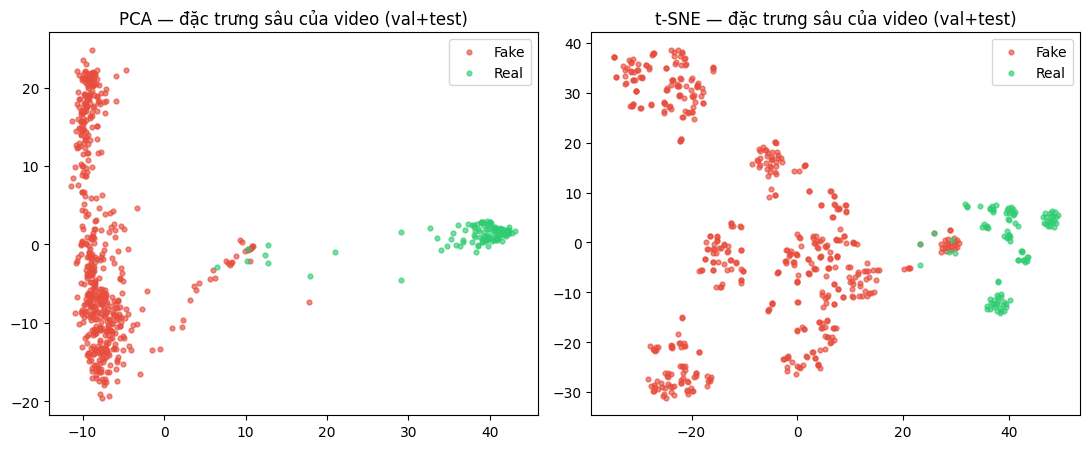

,phương pháp,accuracy,balanced_acc,precision,recall,f1,f1_macro,auc,logloss
0,CNN head (ngưỡng 0.5),0.9872,0.9608,1.0,0.9216,0.9592,0.9758,0.9981,0.0676
1,LogReg trên deep features,0.9872,0.9608,1.0,0.9216,0.9592,0.9758,0.9979,0.0471
2,SVM-RBF trên deep features,0.9872,0.9608,1.0,0.9216,0.9592,0.9758,0.9843,0.0498


In [9]:
if RUN_TRAIN:
    from sklearn.decomposition import PCA
    from sklearn.manifold import TSNE
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import SVC


    @torch.no_grad()
    def extract_embeddings(model, rows, batch=BATCH * 2):
        # Vector đặc trưng (trước lớp phân loại) cho từng khung -> (N, D) float32
        fm = copy.deepcopy(model)
        if ck["arch"].startswith("resnet"):
            fm.fc = nn.Identity()
        else:
            fm.classifier = nn.Identity()
        fm.eval()
        dl = DataLoader(FrameDS(FRAMES_NPY, rows, np.zeros(len(rows), dtype=np.int64)), batch_size=batch,
                        shuffle=False, num_workers=N_WORKERS, pin_memory=IS_GPU)
        out = []
        for xb, _ in tqdm(dl, desc="Trích đặc trưng", leave=False):
            with autocast():
                out.append(fm(to_input(xb, False)).float().cpu().numpy())
        return np.concatenate(out)


    emb = extract_embeddings(best_model, frames_df["row"].values)       # cùng thứ tự với frames_df
    print("Đặc trưng khung hình:", emb.shape)
    np.save(os.path.join(OUT, "deep_features_frames.npy"), emb.astype(np.float16))
    frames_df[["row", "file", "label", "group", "fid", "split"]].to_csv(os.path.join(OUT, "deep_features_frames_index.csv"), index=False)

    # ---- Gộp theo video: mean + std các khung ----
    D = emb.shape[1]
    vrows = []
    for fname, idx in frames_df.groupby("file", sort=False).indices.items():
        e = emb[idx]
        vrows.append(np.concatenate([[frames_df.iloc[idx[0]]["label"]], e.mean(0), e.std(0)]))
    vfeat = pd.DataFrame(np.vstack(vrows), columns=["label"] + ["mean_%d" % i for i in range(D)] + ["std_%d" % i for i in range(D)])
    meta_v = frames_df.drop_duplicates("file")[["file", "group", "split"]].reset_index(drop=True)
    vfeat.insert(0, "file", meta_v["file"].values); vfeat.insert(2, "group", meta_v["group"].values); vfeat.insert(3, "split", meta_v["split"].values)
    vfeat["label"] = vfeat["label"].astype(int)
    vfeat.to_csv(os.path.join(OUT, "deep_features_video.csv"), index=False, float_format="%.5g")
    print("Đặc trưng video: %d video x %d chiều -> deep_features_video.csv" % (len(vfeat), 2 * D))

    # ---- Trực quan hoá: PCA + t-SNE trên đặc trưng mean của video (val + test) ----
    vis = vfeat[vfeat["split"].isin(["val", "test"])]
    Xv_ = StandardScaler().fit_transform(vis[["mean_%d" % i for i in range(D)]].values); yv_ = vis["label"].values
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, (name, red) in zip(axs, (("PCA", PCA(2, random_state=SEED)),
                                     ("t-SNE", TSNE(2, random_state=SEED, init="pca", perplexity=min(30, max(5, (len(Xv_) - 1) // 3)))))):
        Z = red.fit_transform(Xv_)
        for lbl, nm, col in ((0, "Fake", "#e74c3c"), (1, "Real", "#2ecc71")):
            ax.scatter(Z[yv_ == lbl, 0], Z[yv_ == lbl, 1], s=12, alpha=0.65, color=col, label=nm)
        ax.set_title(name + " — đặc trưng sâu của video (val+test)"); ax.legend()
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "deep_features_projection.png"), dpi=150); plt.show()

    # ---- Classifier cổ điển trên đặc trưng sâu (train -> test) ----
    fcols = [c for c in vfeat.columns if c.startswith(("mean_", "std_"))]
    tr_v, te_v = vfeat[vfeat["split"] == "train"], vfeat[vfeat["split"] == "test"]
    sc_v = StandardScaler().fit(tr_v[fcols].values)
    Xtr_v, Xte_v = sc_v.transform(tr_v[fcols].values), sc_v.transform(te_v[fcols].values)
    rows_cmp = [{"phương pháp": "CNN head (ngưỡng 0.5)", **vm_te}]
    for nm, clf in (("LogReg trên deep features", LogisticRegression(max_iter=2000, C=0.05, class_weight="balanced")),
                    ("SVM-RBF trên deep features", SVC(C=2.0, probability=True, class_weight="balanced", random_state=SEED))):
        clf.fit(Xtr_v, tr_v["label"].values)
        rows_cmp.append({"phương pháp": nm, **calc_metrics(te_v["label"].values, clf.predict_proba(Xte_v)[:, list(clf.classes_).index(1)])})
    feat_cmp = pd.DataFrame(rows_cmp)
    feat_cmp.to_csv(os.path.join(OUT, "deep_features_classifier_comparison.csv"), index=False)
    display(feat_cmp.round(4))

## 8. Demo: dự đoán video

`predict_video(path)` chạy lại **toàn bộ pipeline thật** (đọc video → cắt mặt → model) nên dùng được cho video bất kỳ. Demo lấy 4 video Real + 4 video Fake từ **tập test**.

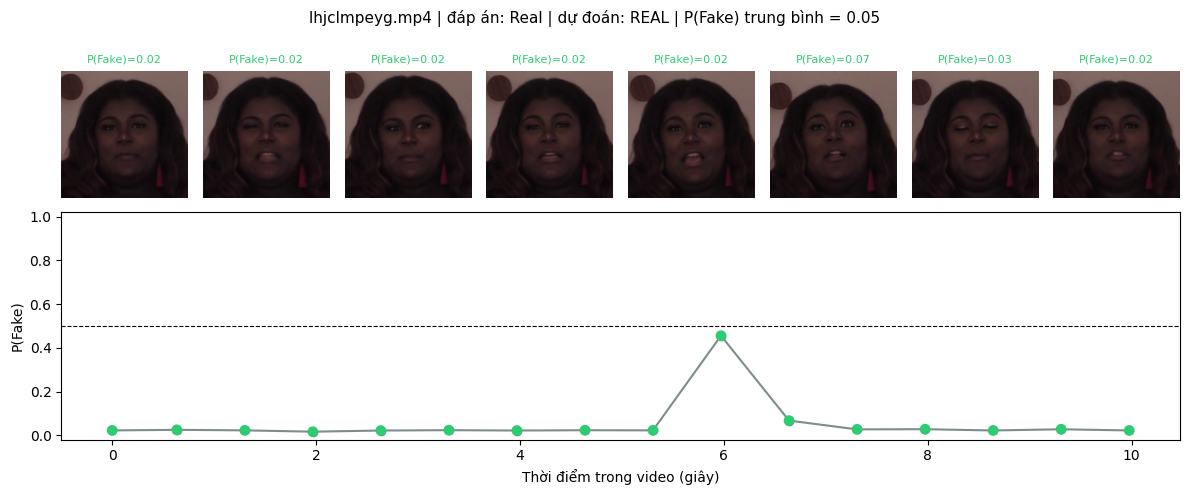

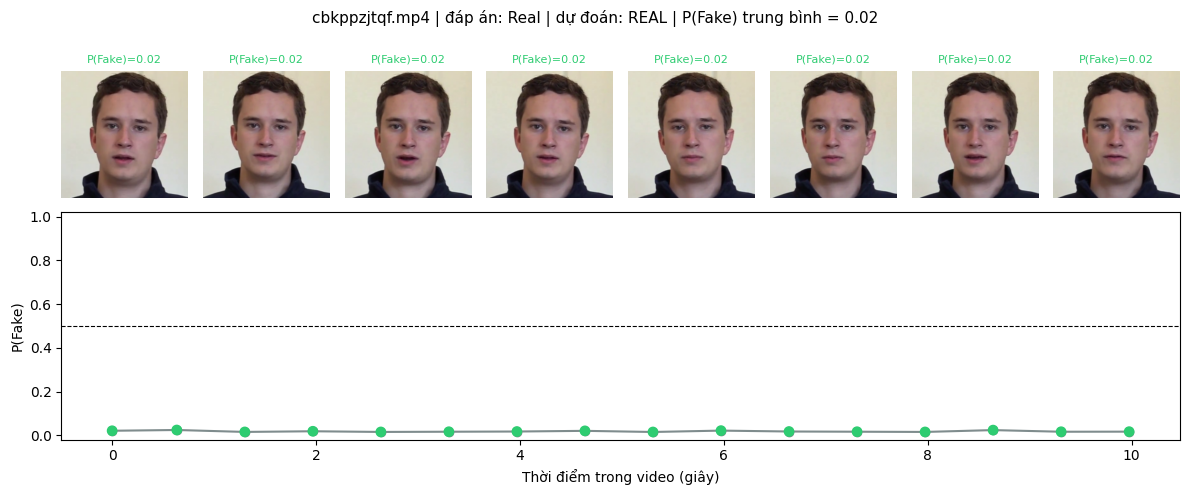

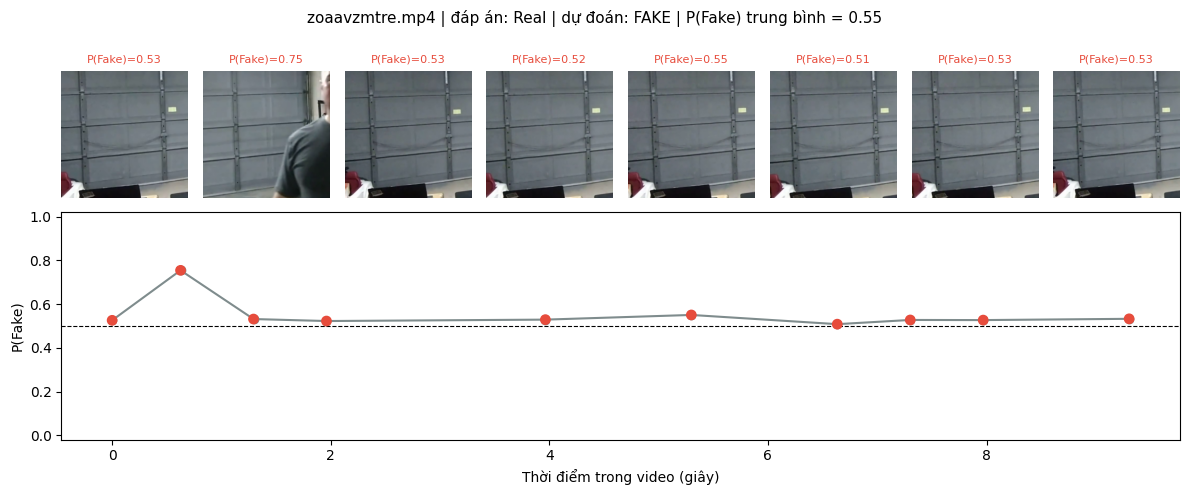

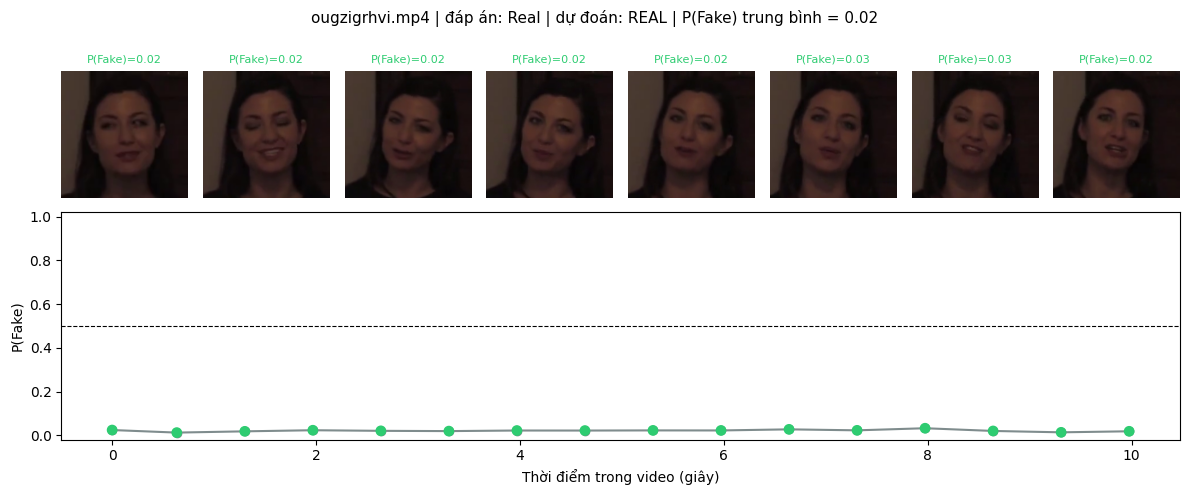

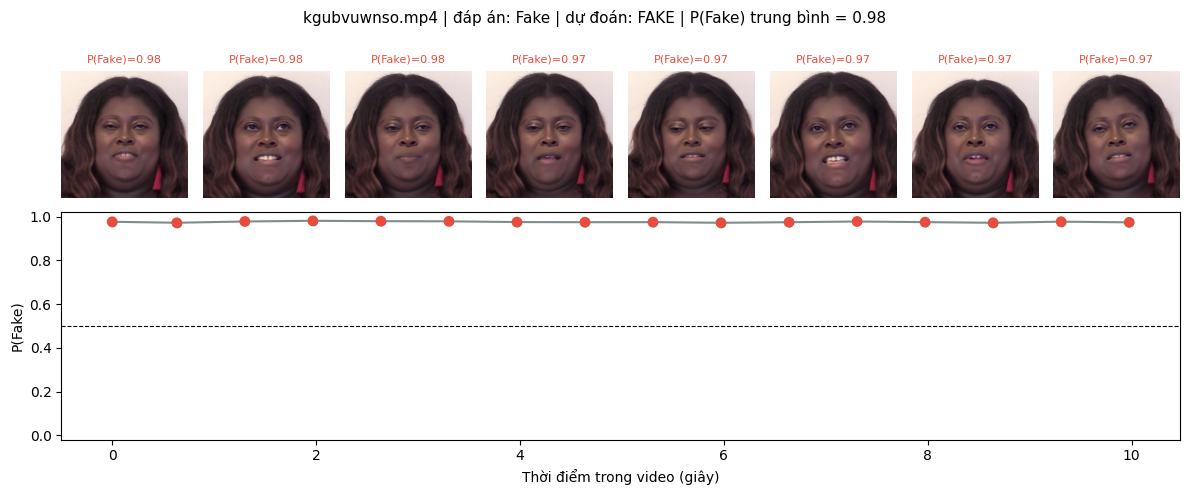

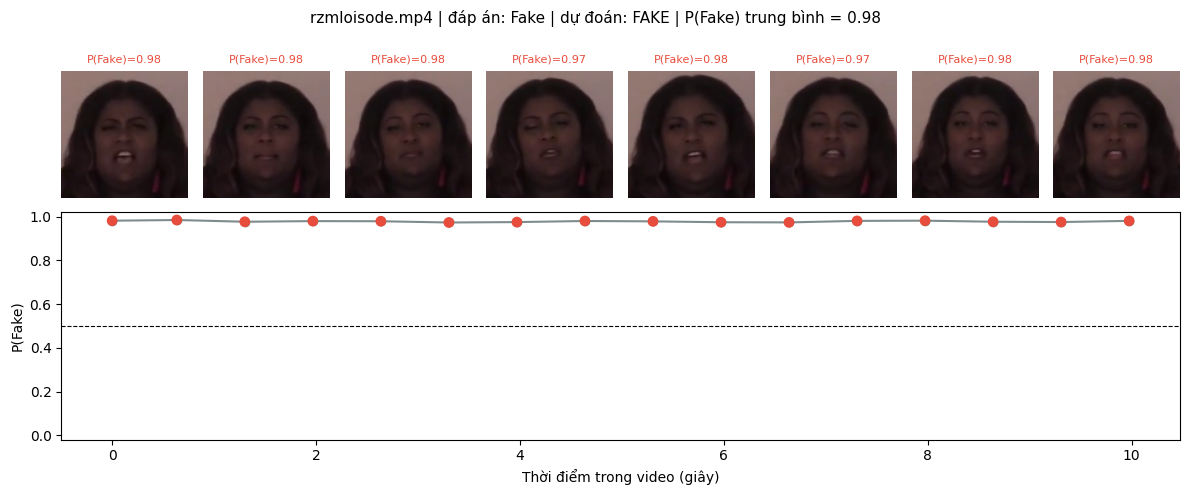

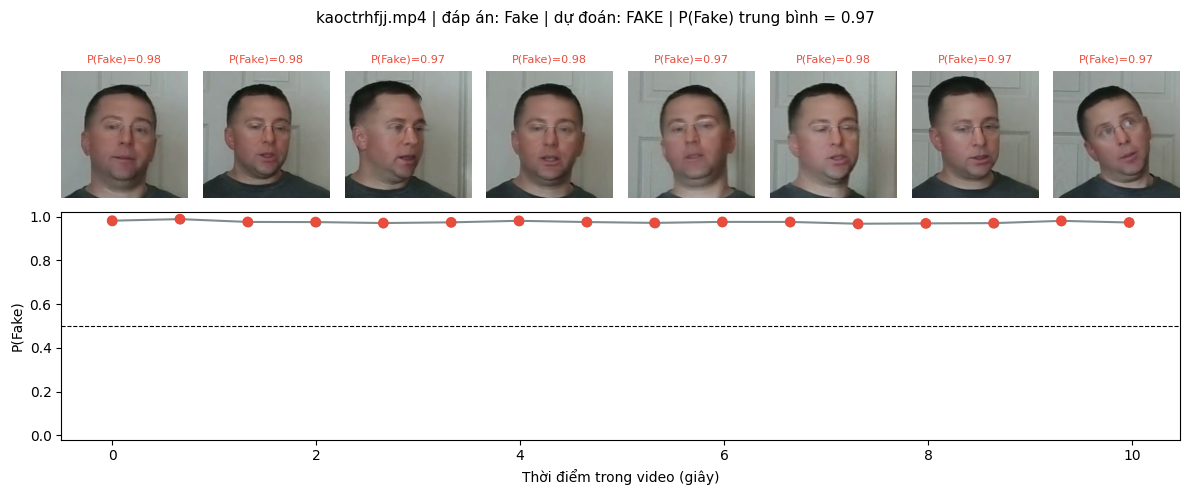

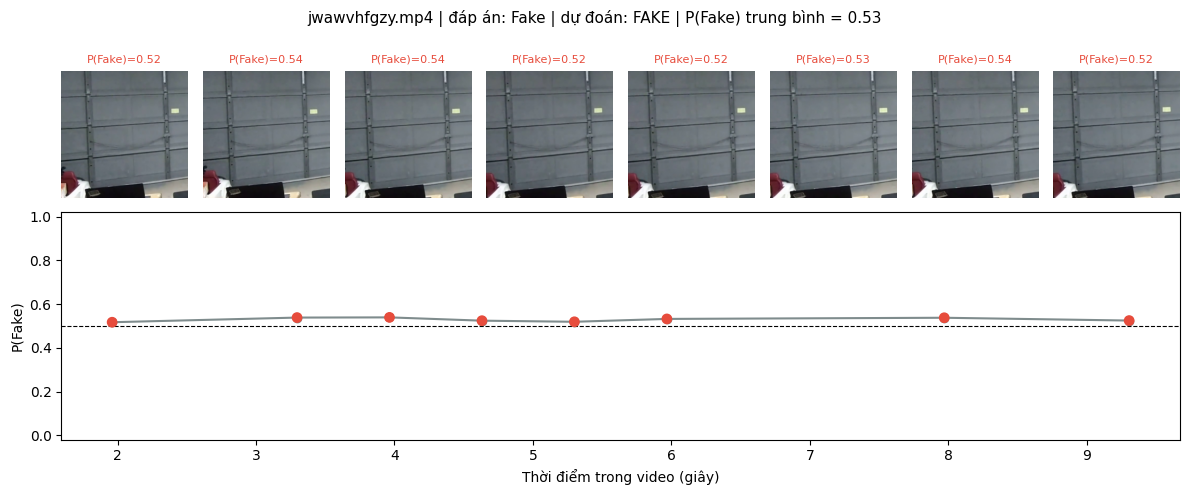

Độ chính xác trên 8 video demo: 88%


,file,truth,pred,p_fake,n_frames,đúng
0,lhjclmpeyg.mp4,Real,Real,0.053,16,True
1,cbkppzjtqf.mp4,Real,Real,0.019,16,True
2,zoaavzmtre.mp4,Real,Fake,0.551,10,False
3,ougzigrhvi.mp4,Real,Real,0.022,16,True
4,kgubvuwnso.mp4,Fake,Fake,0.975,16,True
5,rzmloisode.mp4,Fake,Fake,0.978,16,True
6,kaoctrhfjj.mp4,Fake,Fake,0.975,16,True
7,jwawvhfgzy.mp4,Fake,Fake,0.529,8,True


In [10]:
if RUN_TRAIN:
    truth_map = dict(zip(vid_df["file"], vid_df["label"]))


    def predict_video(path, model=None, thr=0.5, show=True):
        model = model or best_model
        frames, fids, fps = read_frames(path, N_FRAMES)
        det = cv2.CascadeClassifier(CASCADE_XML)
        crops, keep = [], []
        for fr, fid in zip(frames, fids):
            c = crop_face(fr, det, IMG)
            if c is not None:
                crops.append(c); keep.append(fid)
        name = os.path.basename(path)
        if not crops:
            return {"file": name, "truth": None, "pred": "NO_FACE", "p_fake": float("nan"), "n_frames": 0}
        crops = np.stack(crops)
        p_fake = 1.0 - predict_array(model, crops)
        mean_fake = float(p_fake.mean())
        pred = "Fake" if (1.0 - mean_fake) < thr else "Real"
        truth = {1: "Real", 0: "Fake"}.get(truth_map.get(name))
        if show:
            n_show = min(len(crops), 8); pick = np.linspace(0, len(crops) - 1, n_show).astype(int)
            fig = plt.figure(figsize=(12, 5)); gs = fig.add_gridspec(2, n_show, height_ratios=[1, 1.3])
            for k, i in enumerate(pick):
                ax = fig.add_subplot(gs[0, k]); ax.imshow(crops[i]); ax.axis("off")
                ax.set_title("P(Fake)=%.2f" % p_fake[i], fontsize=8, color="#e74c3c" if p_fake[i] >= 0.5 else "#2ecc71")
            ax = fig.add_subplot(gs[1, :])
            ax.plot(np.array(keep) / fps, p_fake, "o-", color="#7f8c8d")
            ax.scatter(np.array(keep) / fps, p_fake, c=["#e74c3c" if v >= 0.5 else "#2ecc71" for v in p_fake], s=45, zorder=3)
            ax.axhline(0.5, color="black", ls="--", lw=0.8); ax.set_ylim(-0.02, 1.02)
            ax.set_xlabel("Thời điểm trong video (giây)"); ax.set_ylabel("P(Fake)")
            fig.suptitle("%s | đáp án: %s | dự đoán: %s | P(Fake) trung bình = %.2f" % (name, truth, pred.upper(), mean_fake), fontsize=11)
            plt.tight_layout(); plt.show()
        return {"file": name, "truth": truth, "pred": pred, "p_fake": round(mean_fake, 3), "n_frames": len(crops)}


    te_vids = vid_df[vid_df["split"] == "test"]
    demo = pd.concat([te_vids[te_vids.label == 1].sample(min(4, (te_vids.label == 1).sum()), random_state=1),
                      te_vids[te_vids.label == 0].sample(min(4, (te_vids.label == 0).sum()), random_state=1)])
    demo_df = pd.DataFrame([predict_video(p) for p in demo["path"]])
    demo_df["đúng"] = demo_df["truth"] == demo_df["pred"]
    print("Độ chính xác trên %d video demo: %.0f%%" % (len(demo_df), 100 * demo_df["đúng"].mean()))
    display(demo_df)

## 9. Tổng kết & file đầu ra

In [11]:
if RUN_TRAIN:
    cfg = {"part": PART, "video_dir": PART_DIR, "arch": ARCH, "img": IMG, "n_frames": N_FRAMES, "epochs_run": len(hist),
           "best_epoch": best["epoch"], "stopped_by_time": stopped_by_time, "threshold_val": THR_VAL, "label_convention": "1=Real, 0=Fake",
           "n_videos": {s: int((vid_df.split == s).sum()) for s in ("train", "val", "test")},
           "test_video": {k: round(v, 4) for k, v in vm_te.items()}}
    with open(os.path.join(OUT, "config.json"), "w", encoding="utf-8") as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)

    print("TEST (mức video, ngưỡng 0.5): " + " | ".join("%s=%.4f" % (k, vm_te[k]) for k in ("accuracy", "balanced_acc", "f1_macro", "auc", "logloss")))
    print("\nFile trong %s:" % OUT)
    for fn in sorted(os.listdir(OUT)):
        print("  %-28s %8.1f KB" % (fn, os.path.getsize(os.path.join(OUT, fn)) / 1024))
    print("\nDùng lại model: ck = torch.load('%s'); build_model(ck['arch'], pretrained=False).load_state_dict(ck['state_dict'])" % BEST_PATH)

TEST (mức video, ngưỡng 0.5): accuracy=0.9872 | balanced_acc=0.9608 | f1_macro=0.9758 | auc=0.9981 | logloss=0.0676

File trong /kaggle/working/outputs_dl:
  config.json                       0.6 KB
  deep_features_classifier_comparison.csv      0.6 KB
  deep_features_frames.npy      67110.1 KB
  deep_features_frames_index.csv   1223.3 KB
  deep_features_projection.png    154.8 KB
  deep_features_video.csv       41720.7 KB
  dl_video_best.pt              15958.4 KB
  dl_video_last.pt              47467.7 KB
  test_evaluation.png              76.3 KB
  test_metrics.csv                  0.6 KB
  test_video_predictions.csv       11.1 KB
  training_curve.png              116.2 KB
  training_history.csv              1.5 KB

Dùng lại model: ck = torch.load('/kaggle/working/outputs_dl/dl_video_best.pt'); build_model(ck['arch'], pretrained=False).load_state_dict(ck['state_dict'])


### Ghi chú

- **Lệch lớp:** part 15 có nhiều Fake hơn Real → xem **balanced accuracy / AUC / log-loss**, đừng chỉ nhìn accuracy.
- **Test chỉ có vài trăm video** nên số liệu dao động; đổi `SEED` để chạy lại với phép chia khác.
- **Detect mặt:** Haar nhanh nhưng bỏ sót mặt nghiêng / bị che. Muốn tốt hơn thay `crop_face` bằng MTCNN / RetinaFace (`facenet-pytorch`) — các phần còn lại giữ nguyên.
- **Nâng cấp:** tăng `N_FRAMES`, `EPOCHS`; đổi `ARCH = "resnet50"`; thêm part DFDC khác bằng cách chạy lại với `PART` khác (hoặc gộp nhiều thư mục vào `vid_df`).
- **Tăng tốc:** cache khung mặt nằm ở `/kaggle/temp/dl_cache` — chạy lại notebook trong cùng session sẽ bỏ qua bước 3.

- **Tiết kiệm GPU:** bước cắt mặt chỉ cần CPU. Chạy lần 1 với GPU tắt (chỉ cắt mặt + lưu cache), lần 2 bật GPU và Add Input output của lần 1. Train tự dừng sau `TIME_LIMIT_H` giờ và lưu `dl_video_last.pt`; Add Input output đó lần sau để train tiếp.
